# KUNCI JAWABAN — Modul 1: Eksplorasi Data untuk Deteksi Anomali

> **JANGAN DIBAGIKAN KE MAHASISWA.** Notebook ini adalah solusi acuan untuk
> `notebooks/modul-01/01_pembuka.ipynb`: seluruh sel `TODO` pada prosedur terbimbing
> Bagian A–D dan kedua Latihan Mandiri di Kelas.

| | |
|---|---|
| **Data** | `generate_lapak.py --seed 2026 --ukuran kecil` (sidik cocok dengan `data/CHECKSUM.txt`) |
| **Diuji dengan** | Python 3.13 dan pandas 2.3.1; kode prosedur naskah juga diuji pada pandas 3.0.5 |
| **Buku ajar** | Bab 2 dan Bab 3 |

Angka pada sel Markdown berbentuk **"Jawaban acuan"** adalah hasil jalan notebook ini
pada seed 2026. Bila kelas memakai seed lain, besarannya sama tetapi digitnya bergeser —
jalankan ulang notebook ini, jangan menyalin angkanya.

**Perbedaan dengan versi mahasiswa:** mahasiswa menulis keluaran ke
`modul-01-eksplorasi/keluaran/`; kunci ini menulis ke `keluaran/` di sebelah notebook.

## Bagian A — Membaca data mentah secara aman

### A.1 Menentukan akar repositori

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "raw").is_dir())
RAW = ROOT / "data" / "raw"
OUT = Path.cwd() / "keluaran"          # versi mahasiswa: ROOT / "modul-01-eksplorasi" / "keluaran"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)
print("Akar repositori :", ROOT.name)
print("pandas          :", pd.__version__)

Akar repositori : Praktikum
pandas          : 2.3.1


### A.2 Membaca dua kali

In [2]:
# 1) Apa adanya: semua kolom teks, tidak ada token yang diubah menjadi NaN.
mentah = pd.read_csv(RAW / "transaksi.csv", dtype=str, keep_default_na=False)

# 2) Dengan inferensi tipe bawaan pandas.
tebak = pd.read_csv(RAW / "transaksi.csv")

print(mentah.shape, tebak.shape)
banding = pd.DataFrame({"tebakan_pandas": tebak.dtypes.astype(str),
                        "nilai_kosong_setelah_tebak": tebak.isna().sum()})
banding

(24288, 18) (24288, 18)


,tebakan_pandas,nilai_kosong_setelah_tebak
id_pesanan,object,0
baris_ke,int64,0
kanal,object,0
id_pelanggan,object,418
kode_produk,object,0
jumlah,int64,0
harga_satuan,float64,0
diskon_persen,float64,0
ongkir,object,1075
total_bayar,float64,0


In [3]:
def token_bukan_angka(seri: pd.Series) -> pd.Series:
    """Frekuensi nilai teks yang gagal dikonversi menjadi angka."""
    angka = pd.to_numeric(seri, errors="coerce")
    return seri[angka.isna()].value_counts(dropna=False)

for kolom in ["jumlah", "harga_satuan", "diskon_persen", "ongkir",
              "total_bayar", "lama_kirim_hari", "rating_ulasan"]:
    token = token_bukan_angka(mentah[kolom])
    if len(token):
        print(f"{kolom:<16}", {repr(k): int(v) for k, v in token.items()})

ongkir           {"''": 1075, "'-'": 36}
lama_kirim_hari  {"''": 3239}
rating_ulasan    {"''": 7496}


**Jawaban acuan A.2**

1. Kedua pembacaan menghasilkan **24.288 baris × 18 kolom**. Jumlah baris sama; yang berbeda adalah *isi* sel.
2. `ongkir` secara makna adalah angka, tetapi ditebak sebagai **teks** (`object` pada pandas 2, `str` pada pandas 3). Penyebabnya token **`"-"` pada 36 baris**. Satu token saja cukup untuk mengubah tipe seluruh kolom.
3. Pada pembacaan bawaan, `ongkir` kosong terhitung **1.075**, padahal sel yang tidak dapat dipakai sebagai angka ada **1.111** (1.075 kosong + 36 `"-"`). Token `"-"` lolos sebagai teks dan tidak terhitung kosong.
4. `lama_kirim_hari` (3.239 kosong) dan `rating_ulasan` (7.496 kosong) ditebak `float64` karena kekosongan — bukan karena nilainya pecahan.
5. `id_pelanggan` kosong **418 baris**. Pembacaan bawaan mengubahnya menjadi `NaN`, sehingga tidak dapat dibedakan lagi dari string kosong.
6. Yang **tidak** tertangkap A.2: penanda numerik `999`, `-1`, dan rating `0`. Semuanya lolos sebagai angka valid. Ini sengaja — ditemukan pada C.1.

*Pertanyaan balik untuk mahasiswa yang langsung memakai `errors="coerce"` sebagai perbaikan:*
"Setelah `to_numeric`, berapa baris ongkir yang kosong? Dari mana Anda tahu 36 di antaranya aslinya bukan kosong?"

## Bagian B — Profil struktur dan kualitas

### B.1 Profil per kolom

In [4]:
def profil_kolom(df_teks: pd.DataFrame) -> pd.DataFrame:
    baris = []
    for kolom in df_teks.columns:
        s = df_teks[kolom]
        kosong = s.str.strip().eq("")
        angka = pd.to_numeric(s[~kosong], errors="coerce")
        porsi_angka = angka.notna().mean() if (~kosong).any() else 0.0
        baris.append({
            "kolom": kolom,
            "kosong": int(kosong.sum()),
            "persen_kosong": round(100 * kosong.mean(), 2),
            "nilai_unik": s[~kosong].nunique(),
            "porsi_numerik": round(porsi_angka, 3),
            "min_numerik": angka.min() if porsi_angka > 0.9 else None,
            "maks_numerik": angka.max() if porsi_angka > 0.9 else None,
            "contoh": list(s[~kosong].drop_duplicates().head(3)),
        })
    return pd.DataFrame(baris)

profil = profil_kolom(mentah)
profil.to_csv(OUT / "profil_transaksi.csv", index=False)
profil

,kolom,kosong,persen_kosong,nilai_unik,porsi_numerik,min_numerik,maks_numerik,contoh
0,id_pesanan,0,0.00,15840,0.000,NaN,NaN,"[LS-2025-006807, LS-2025-009886, LS-2025-005990]"
1,baris_ke,0,0.00,3,1.000,1.0,3.0,"[1, 2, 3]"
2,kanal,0,0.00,2,0.000,NaN,NaN,"[web, app]"
3,id_pelanggan,418,1.72,5355,0.000,NaN,NaN,"[W-00931, W-00310, W-00632]"
4,kode_produk,0,0.00,926,0.000,NaN,NaN,"[LS-KER-0821, LS-KOP-0282, LS-KAI-0275]"
5,jumlah,0,0.00,75,1.000,-5.0,198.0,"[5, 1, 4]"
6,harga_satuan,0,0.00,473,1.000,10500.0,146250000.0,"[563500.0, 42500.0, 926500.0]"
7,diskon_persen,0,0.00,11,1.000,0.0,25.0,"[0.0, 15.0, 5.0]"
8,ongkir,1075,4.43,281,0.998,12000.0,1029000.0,"[38500.0, 14000.0, 22500.0]"
9,total_bayar,0,0.00,9196,1.000,19875.0,27243000.0,"[2856000.0, 56500.0, 3728500.0]"


**Jawaban acuan B.1**

- Kolom campuran (`porsi_numerik` di antara 0 dan 1): hanya **`ongkir`** (0,998) — konsisten dengan temuan A.2.
- `nilai_unik` terlalu besar untuk kolom kategorikal: `metode_bayar` **16** (seharusnya 5), `status` **8** (seharusnya 4), `provinsi_tujuan` **20** (seharusnya 10), `kota_tujuan` **28** (seharusnya 10).
- `kurir` 5 dan `kanal` 2 sesuai kamus data — laporkan juga sebagai temuan nol; itu informasi.
- `min_numerik` `jumlah` = −5, `lama_kirim_hari` = −1 dan maks 999, `rating_ulasan` min 0: ketiganya melanggar kamus data.

*Kesalahan lazim:* profil dibangun dari DataFrame hasil inferensi, sehingga `persen_kosong` `id_pelanggan` benar tetapi `ongkir` "-" tidak pernah muncul.

### B.2 Statistik deskriptif

In [5]:
kolom_angka = ["jumlah", "harga_satuan", "diskon_persen", "ongkir",
               "total_bayar", "lama_kirim_hari", "rating_ulasan"]
angka = mentah[kolom_angka].apply(pd.to_numeric, errors="coerce")

ringkas = angka.describe(percentiles=[.01, .25, .5, .75, .99]).T
ringkas["rasio_mean_median"] = (ringkas["mean"] / ringkas["50%"]).round(2)
ringkas.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max,rasio_mean_median
jumlah,24288.0,2.81,8.25,-5.0,1.0,1.0,2.0,4.0,5.0,198.0,1.41
harga_satuan,24288.0,248658.45,2401478.85,10500.0,13000.0,39000.0,63000.0,140500.0,1405500.0,146250000.0,3.95
diskon_persen,24288.0,9.04,9.15,0.0,0.0,0.0,5.0,15.0,25.0,25.0,1.81
ongkir,23177.0,21104.95,27581.74,12000.0,12000.0,13500.0,15500.0,20000.0,90500.0,1029000.0,1.36
total_bayar,24288.0,405108.17,961440.18,19875.0,28500.0,75000.0,144000.0,330000.0,4278237.0,27243000.0,2.81
lama_kirim_hari,21049.0,7.37,65.74,-1.0,1.0,2.0,3.0,4.0,14.0,999.0,2.46
rating_ulasan,16792.0,3.53,1.72,0.0,0.0,3.0,4.0,5.0,5.0,5.0,0.88


**Jawaban acuan B.2**

| Kolom | Mean | Median | Rasio | Dugaan penyebab |
|---|---:|---:|---:|---|
| `harga_satuan` | 248.658 | 63.000 | **3,95** | Maks 146.250.000 dan p99 1.405.500: nilai ~100× harga wajar (salah ketik nol) ditambah miring alami kain tenun |
| `total_bayar` | 405.108 | 144.000 | **2,81** | Ikut terdorong harga ×100 dan pembelian grosir |
| `lama_kirim_hari` | 7,37 | 3 | **2,46** | Maks **999** (penanda) dan min **−1**; p99 hanya 14 |
| `diskon_persen` | 9,04 | 5 | 1,81 | Distribusi diskret dengan banyak 0 — **bukan** pencilan; median kurang informatif di sini |
| `jumlah` | 2,81 | 2 | 1,41 | p99 = 5 tetapi maks 198 (grosir) dan min −5 |
| `ongkir` | 21.105 | 15.500 | 1,36 | Maks 1.029.000 pada pembelian grosir berat |
| `rating_ulasan` | 3,53 | 4 | **0,88** | Rasio < 1: ekor kiri oleh **nilai 0** yang di luar skala 1–5 |

Poin penilaian: mahasiswa yang hanya melihat rasio akan melewatkan `lama_kirim_hari` p99 = 14 vs maks 999 dan `rating_ulasan` min 0. Rasio adalah petunjuk, min/maks/persentil adalah bukti.

### B.3 Nilai kategorikal

In [6]:
for kolom in ["kanal", "metode_bayar", "status", "kurir", "provinsi_tujuan"]:
    print(f"\n== {kolom} ({mentah[kolom].nunique()} nilai unik)")
    print(mentah[kolom].value_counts().to_string())

print("\n== kota_tujuan, 30 teratas (repr memperlihatkan spasi di ujung)")
print({repr(k): int(v) for k, v in mentah.kota_tujuan.value_counts().head(30).items()})


== kanal (2 nilai unik)
kanal
web    13174
app    11114

== metode_bayar (16 nilai unik)
metode_bayar
GoPay              2180
e-wallet           2095
transfer           2072
Transfer Bank      2053
E-Wallet           2040
Transfer bank      2010
OVO                2000
EWALLET            1940
cod                1511
COD                1473
Bayar di Tempat    1381
PayLater            986
Paylater            934
CC                  556
kartu kredit        534
Kartu Kredit        523

== status (8 nilai unik)
status
selesai         19671
diproses         1614
dibatalkan       1582
dikembalikan      955
SELESAI           401
DIPROSES           22
DIKEMBALIKAN       22
DIBATALKAN         21

== kurir (5 nilai unik)
kurir
SiCepat          4919
Pos Indonesia    4895
AnterAja         4863
JNE              4844
J&T              4767

== provinsi_tujuan (20 nilai unik)
provinsi_tujuan
Lampung                      2118
LAMPUNG                      2094
Sumut                        1698
Sumatera 

**Jawaban acuan B.3**

| Kolom | Unik | Seharusnya | Varian yang ditemukan |
|---|---:|---:|---|
| `metode_bayar` | 16 | 5 | `E-Wallet`/`e-wallet`/`EWALLET`/`OVO`/`GoPay`; `Transfer Bank`/`Transfer bank`/`transfer`; `COD`/`cod`/`Bayar di Tempat`; `Kartu Kredit`/`kartu kredit`/`CC`; `Paylater`/`PayLater` |
| `status` | 8 | 4 | huruf kapital (`SELESAI`, `DIBATALKAN`, …) |
| `provinsi_tujuan` | 20 | 10 | singkatan (`Sumut`, `Sumsel`, `Babel`, `Kepri`, `NAD`), ejaan `Sumatra Utara`, huruf kapital |
| `kota_tujuan` | 28 | 10 | `Kota X`, huruf kapital, `Plg`, `B. Lampung`, `Bandarlampung`, `Pekan Baru`, `Pangkal Pinang`, dan **`'MEDAN '` dengan spasi di ujung** |

Jebakan yang membedakan jawaban kuat: `OVO` dan `GoPay` adalah **merek**, bukan sekadar variasi penulisan — memetakannya ke `E-Wallet` adalah keputusan bisnis yang perlu dicatat (Modul 4). `'MEDAN '` tampak identik dengan `MEDAN` pada `value_counts()` biasa; hanya terlihat dengan `repr` atau `str.strip()`.

## Bagian C — Mendeteksi anomali

### C.1 Menguji aturan bisnis

In [7]:
t = mentah.copy()
num = angka
subtotal = num.jumlah * num.harga_satuan * (1 - num.diskon_persen / 100)
status_bersih = t.status.str.lower()

aturan = {
    "jumlah_tidak_positif":   num.jumlah < 1,
    "diskon_di_luar_0_50":    ~num.diskon_persen.between(0, 50),
    "diskon_pecahan":         num.diskon_persen.between(0, 1, inclusive="neither"),
    "total_tidak_cocok":      (num.total_bayar - (subtotal + num.ongkir)).abs() > 1,
    "lama_kirim_di_luar_1_30": num.lama_kirim_hari.notna()
                               & ~num.lama_kirim_hari.between(1, 30),
    "lama_kirim_pada_status_salah":
        num.lama_kirim_hari.notna() & ~status_bersih.isin(["selesai", "dikembalikan"]),
    "rating_di_luar_1_5":     num.rating_ulasan.notna() & ~num.rating_ulasan.between(1, 5),
    "rating_pada_status_bukan_selesai":
        num.rating_ulasan.notna() & status_bersih.ne("selesai"),
    "status_huruf_kapital":   t.status.ne(status_bersih),
    "pelanggan_kosong_di_app": t.id_pelanggan.eq("") & t.kanal.eq("app"),
    "prefiks_pelanggan_tidak_sesuai_kanal":
        t.id_pelanggan.ne("")
        & ~((t.kanal.eq("web") & t.id_pelanggan.str.startswith("W-"))
            | (t.kanal.eq("app") & t.id_pelanggan.str.startswith("A-"))),
}

hasil = pd.DataFrame({
    "baris_melanggar": {k: int(m.sum()) for k, m in aturan.items()},
    "persen": {k: round(100 * m.mean(), 2) for k, m in aturan.items()},
})
hasil.sort_values("baris_melanggar", ascending=False)

,baris_melanggar,persen
rating_di_luar_1_5,2805,11.55
total_tidak_cocok,751,3.09
diskon_pecahan,515,2.12
status_huruf_kapital,466,1.92
lama_kirim_di_luar_1_30,127,0.52
jumlah_tidak_positif,70,0.29
diskon_di_luar_0_50,0,0.00
lama_kirim_pada_status_salah,0,0.00
rating_pada_status_bukan_selesai,0,0.00
pelanggan_kosong_di_app,0,0.00


In [8]:
# Membedah pelanggaran yang bercampur
lama = num.lama_kirim_hari
print("lama_kirim 999           :", int((lama == 999).sum()))
print("lama_kirim -1            :", int((lama == -1).sum()))
print("lama_kirim 18-30 (sah?)  :", int(lama.between(18, 30).sum()),
      t.loc[lama.between(18, 30), "kurir"].value_counts().to_dict())

print("\nrating 0 per kanal       :", t.loc[num.rating_ulasan == 0, "kanal"].value_counts().to_dict())
print("rata-rata rating dg 0    :", num.rating_ulasan.groupby(t.kanal).mean().round(3).to_dict())
print("rata-rata rating tanpa 0 :", num.rating_ulasan.where(num.rating_ulasan > 0)
      .groupby(t.kanal).mean().round(3).to_dict())

rasio_harga = num.harga_satuan / num.harga_satuan.groupby(t.kode_produk).transform("median")
harga_x100 = rasio_harga >= 50
tidak_cocok = aturan["total_tidak_cocok"]
print("\ntotal_tidak_cocok        :", int(tidak_cocok.sum()))
print("  ... bersamaan diskon pecahan :", int((tidak_cocok & aturan["diskon_pecahan"]).sum()))
print("  ... bersamaan harga >=50x    :", int((tidak_cocok & harga_x100).sum()))
print("  ... sisanya                  :", int((tidak_cocok & ~aturan["diskon_pecahan"] & ~harga_x100).sum()))
print("baris tidak dapat diperiksa (ongkir bukan angka):", int(num.ongkir.isna().sum()))

lama_kirim 999           : 92
lama_kirim -1            : 35
lama_kirim 18-30 (sah?)  : 115 {'Pos Indonesia': 114, 'J&T': 1}

rating 0 per kanal       : {'app': 2805}
rata-rata rating dg 0    : {'app': 2.951, 'web': 4.237}
rata-rata rating tanpa 0 : {'app': 4.25, 'web': 4.237}

total_tidak_cocok        : 751
  ... bersamaan diskon pecahan : 463
  ... bersamaan harga >=50x    : 113
  ... sisanya                  : 177
baris tidak dapat diperiksa (ongkir bukan angka): 1111


**Jawaban acuan C.1**

| Aturan | Baris | % | Catatan |
|---|---:|---:|---|
| `rating_di_luar_1_5` | 2.805 | 11,55 | **Seluruhnya bernilai 0 dan seluruhnya kanal `app`** |
| `total_tidak_cocok` | 751 | 3,09 | Campuran: 463 bersamaan diskon pecahan, 113 bersamaan harga ≥50×, 177 selisih murni (umumnya +Rp10.000) |
| `diskon_pecahan` | 515 | 2,12 | Diskon ditulis 0,05–0,25, bukan 5–25 |
| `status_huruf_kapital` | 466 | 1,92 | |
| `lama_kirim_di_luar_1_30` | 127 | 0,52 | = 92 penanda `999` + 35 penanda `-1` |
| `jumlah_tidak_positif` | 70 | 0,29 | −1 s.d. −5 |
| lima aturan lain | 0 | 0 | Laporkan sebagai temuan nol |

Tiga hal yang membedakan jawaban bernilai penuh:

1. **Rating 0 adalah penanda nilai hilang.** Rata-rata rating app 2,951 dengan 0 vs **4,250** tanpa 0; web 4,237. Dengan nol, app tampak jauh lebih buruk — kesimpulan yang sepenuhnya artefak pencatatan.
2. **1.111 baris tidak dapat diperiksa** oleh `total_tidak_cocok` karena ongkir kosong atau `"-"`. Mahasiswa yang menyebut keterbatasan ini memenuhi catatan pada naskah.
3. **115 baris lama kirim 18–30 hari** lolos aturan dan hampir seluruhnya kurir Pos Indonesia — pengiriman lambat yang *sah*, bukan anomali. Bahan diskusi Modul 3.

### C.2 Format dan rentang waktu

In [9]:
pola = {
    "iso_spasi":  r"^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}$",
    "iso_T_Z":    r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}Z$",
    "dd/mm/yyyy": r"^\d{2}/\d{2}/\d{4} \d{2}:\d{2}$",
}
t["pola_waktu"] = "lainnya"
for nama, regex in pola.items():
    t.loc[t.waktu_pesan.str.match(regex), "pola_waktu"] = nama

print(pd.crosstab(t.pola_waktu, t.kanal))

tahun = t.waktu_pesan.str.extract(r"(\d{4})")[0].astype(int)
print("\n", tahun.value_counts().sort_index().to_dict())
print("\nBaris bertahun 2024:")
print(t.loc[tahun == 2024, ["id_pesanan", "waktu_pesan", "kanal"]].to_string())
print("\nKanal bertahun 1970:", t.loc[tahun == 1970, "kanal"].value_counts().to_dict(),
      "| 2062:", t.loc[tahun == 2062, "kanal"].value_counts().to_dict())

kanal         app    web
pola_waktu              
dd/mm/yyyy      0   1957
iso_T_Z     11114      0
iso_spasi       0  11217

 {1970: 13, 2024: 5, 2025: 14951, 2026: 9314, 2062: 5}

Baris bertahun 2024:
        id_pesanan           waktu_pesan kanal
6   LS-2025-002789  2024-12-31T19:45:01Z   app
7   LS-2025-002789  2024-12-31T19:45:01Z   app
8   LS-2025-015595  2024-12-31T20:23:49Z   app
9   LS-2025-015595  2024-12-31T20:23:49Z   app
10  LS-2025-015595  2024-12-31T20:23:49Z   app

Kanal bertahun 1970: {'web': 13} | 2062: {'app': 3, 'web': 2}


**Jawaban acuan C.2**

- Tiga pola, **tanpa** pola `lainnya`. Tabel silang memperlihatkan pemisahan sempurna: `iso_T_Z` **11.114 baris hanya kanal `app`**; `iso_spasi` 11.217 dan `dd/mm/yyyy` 1.957 hanya kanal `web`.
- Tahun: 1970 (**13**, seluruhnya web, `1970-01-01 07:00:00`), 2024 (5), 2025 (14.951), 2026 (9.314), 2062 (**5**).
- **1970-01-01 07:00:00** = epoch Unix 0 dalam WIB (UTC+7): nilai bawaan sistem ketika waktu tidak terisi.
- **2062** adalah salah ketik 2026 (digit tertukar).
- **Lima baris bertahun 2024 bukan anomali** — ini temuan paling tajam di modul ini. Semuanya kanal app, sekitar `2024-12-31T19:45Z`–`20:23Z`, yaitu **1 Januari 2025 pukul 02:45–03:23 WIB**. Akhiran `Z` berarti UTC; transaksi baru mulai 1 Januari 2025. Kesimpulan: **kanal app mencatat waktu dalam UTC**, sehingga pembandingan jam antarkanal meleset 7 jam (ditangani Modul 4).

*Pertanyaan balik:* "Kalau platform diluncurkan Juli 2024, apakah pesanan Desember 2024 mustahil? Lalu mengapa hanya ada lima dan semuanya menjelang tengah malam UTC?"

### C.3 Visualisasi

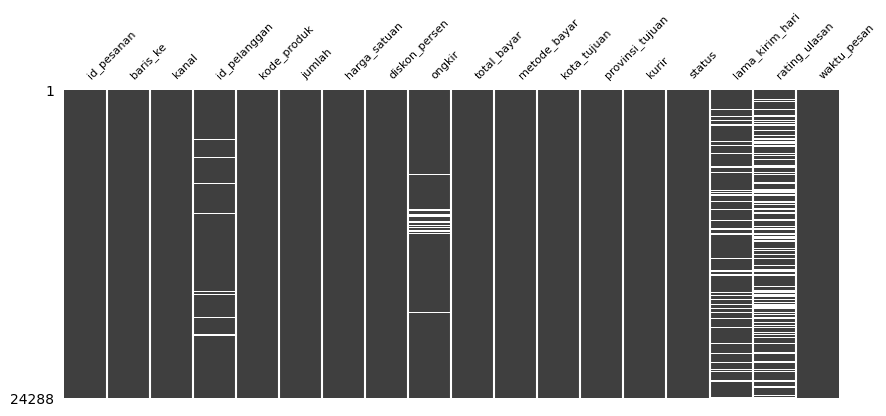

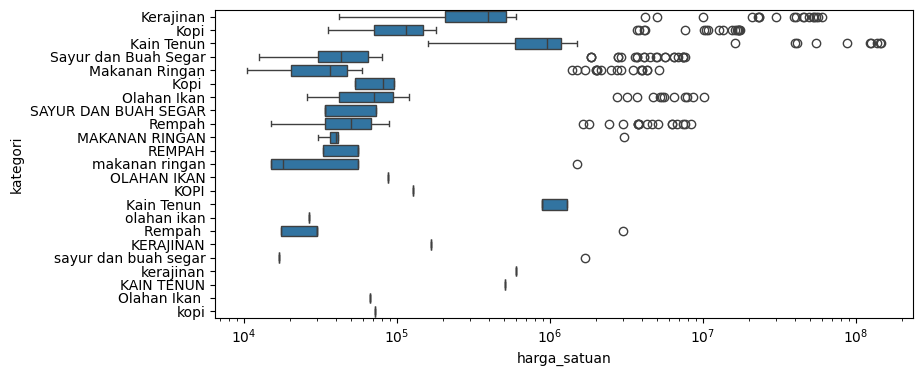

In [10]:
import missingno as msno

# 1) Pola nilai hilang. String kosong diubah menjadi NaN hanya untuk grafik.
ax = msno.matrix(t.replace("", np.nan).drop(columns="pola_waktu"),
                 figsize=(10, 4), fontsize=8, sparkline=False)
ax.get_figure().savefig(OUT / "01_pola_nilai_hilang.png", dpi=120, bbox_inches="tight")
plt.show()

# 2) Boxplot harga satuan per kategori produk, sumbu logaritmik.
produk = pd.read_csv(RAW / "produk.csv", dtype=str, keep_default_na=False)
kat = t.merge(produk[["kode_produk", "kategori"]], on="kode_produk", how="left")
kat["harga_satuan"] = pd.to_numeric(kat.harga_satuan, errors="coerce")
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=kat, x="harga_satuan", y="kategori", ax=ax)
ax.set_xscale("log")
fig.savefig(OUT / "02_boxplot_harga.png", dpi=120, bbox_inches="tight")
plt.show()

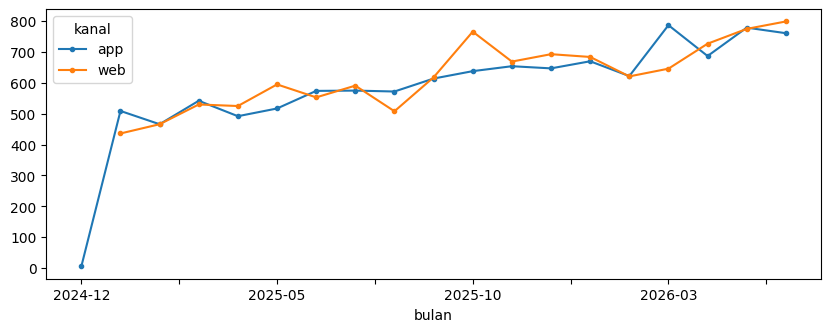

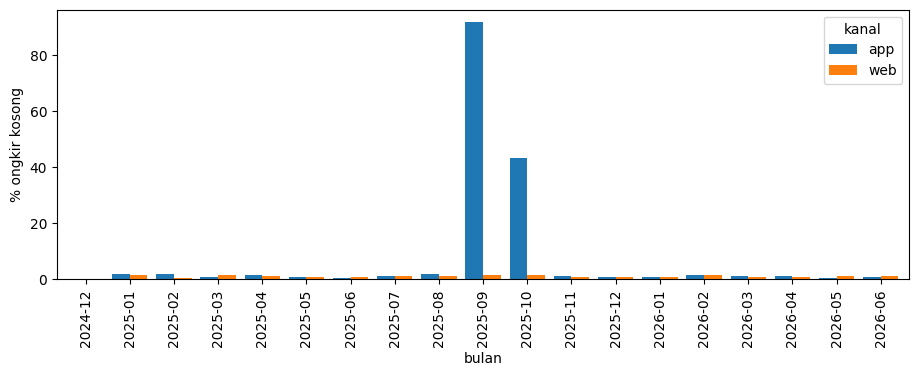

kanal     app  web
bulan             
2025-07   1.0  1.0
2025-08   1.9  1.2
2025-09  91.5  1.5
2025-10  43.3  1.3
2025-11   1.1  0.7


In [11]:
# 3) Jumlah baris per bulan (dari teks tanggal, format ISO saja).
iso = t[t.pola_waktu.isin(["iso_spasi", "iso_T_Z"])].copy()
iso["bulan"] = iso.waktu_pesan.str[:7]
per_bulan = iso[iso.bulan.between("2024-07", "2026-06")] \
    .groupby(["bulan", "kanal"]).size().unstack()
ax = per_bulan.plot(figsize=(10, 3.5), marker=".")
ax.get_figure().savefig(OUT / "03_baris_per_bulan.png", dpi=120, bbox_inches="tight")
plt.show()

# 4) Persentase ongkir kosong per bulan per kanal.
iso["ongkir_kosong"] = iso.ongkir.eq("")
kosong = iso[iso.bulan.between("2024-07", "2026-06")] \
    .groupby(["bulan", "kanal"]).ongkir_kosong.mean().unstack() * 100
ax = kosong.plot(kind="bar", figsize=(11, 3.5), width=.8)
ax.set_ylabel("% ongkir kosong")
ax.get_figure().savefig(OUT / "04_ongkir_kosong_per_bulan.png", dpi=120, bbox_inches="tight")
plt.show()

print(kosong.round(1).loc["2025-07":"2025-11"])

**Jawaban acuan C.3 — dua kalimat per grafik**

1. **Pola nilai hilang.** Kekosongan hanya ada pada `id_pelanggan`, `ongkir`, `lama_kirim_hari`, dan `rating_ulasan`; empat belas kolom lain lengkap. Karena berkas terurut menurut waktu, kekosongan `ongkir` yang **menumpuk sebagai satu pita di sekitar pertengahan berkas** menandakan satu periode tertentu (dikonfirmasi grafik 4), sedangkan `rating_ulasan` tersebar di seluruh periode dan jauh lebih padat daripada `lama_kirim_hari`. Grafik ini tidak menampilkan 36 token `"-"` dan 2.805 rating 0 — penanda yang tidak kosong tidak terlihat sebagai kekosongan.
2. **Boxplot harga per kategori.** Setiap kategori memiliki titik di ujung kanan yang terpisah sekitar dua orde besaran (×100) dari kotaknya — pola salah ketik nol, bukan variasi harga. Varian penulisan kategori (`Kopi ` dengan spasi, `KOPI`, `makanan ringan`) muncul sebagai 23 kotak terpisah alih-alih 7, dan 77 baris berkode produk yatim **hilang diam-diam** dari grafik karena kategorinya kosong setelah `merge`.
3. **Baris per bulan.** Volume kedua kanal naik bertahap dari ~450–500 baris per bulan pada awal 2025 menjadi ~750–800 pada pertengahan 2026, tanpa celah bulan. Titik app pada 2024-12 (5 baris) adalah artefak UTC dari C.2, bukan transaksi sebelum 2025.
4. **Ongkir kosong per bulan.** Di luar satu periode, kekosongan stabil ~1% di kedua kanal. Pada kanal app **September 2025 melonjak ke 91,5% dan Oktober 43,3%**, sementara web tetap ~1,5% — kekosongan bergantung pada kanal dan waktu yang *teramati* (petunjuk ke MAR, diuji Modul 2).

Grafik 4 tidak membuktikan "aplikasi rusak". Jawaban bernilai penuh menulis pola + dugaan + pemeriksaan pembuktian (mis. membandingkan versi aplikasi, atau apakah `total_bayar` tetap terisi sehingga ongkir dapat diturunkan).

### C.4 Duplikasi dan integritas relasi

In [12]:
dup_eksak = t.drop(columns="pola_waktu").duplicated(keep=False)
dup_kunci = t.duplicated(["id_pesanan", "baris_ke"], keep=False)
print("Baris terlibat duplikat eksak      :", int(dup_eksak.sum()))
print("  ... salinan berlebih (keep=first):", int(t.drop(columns="pola_waktu").duplicated().sum()))
print("Baris terlibat duplikat kunci      :", int(dup_kunci.sum()))
print("Duplikat kunci yang bukan eksak    :", int((dup_kunci & ~dup_eksak).sum()))

yatim = ~t.kode_produk.isin(produk.kode_produk)
print("Baris dengan kode_produk tak dikenal:", int(yatim.sum()),
      t.loc[yatim, "kode_produk"].str[:6].value_counts().to_dict())

# Melampaui prosedur: pesanan terkirim ulang dengan nomor pesanan BARU
kolom_tanpa_id = [c for c in t.columns if c not in ("id_pesanan", "pola_waktu")]
dekat = t.duplicated(kolom_tanpa_id, keep=False) & ~dup_eksak
print("Baris identik kecuali id_pesanan   :", int(dekat.sum()))

Baris terlibat duplikat eksak      : 384
  ... salinan berlebih (keep=first): 192
Baris terlibat duplikat kunci      : 384
Duplikat kunci yang bukan eksak    : 0
Baris dengan kode_produk tak dikenal: 77 {'LS-UNK': 77}
Baris identik kecuali id_pesanan   : 191


**Jawaban acuan C.4**

- Duplikat eksak: **384 baris terlibat**, yaitu **192 salinan berlebih**. Keduanya benar asalkan definisinya disebut; jawaban yang hanya menulis "ada duplikat" tanpa definisi dikurangi.
- Duplikat kunci 384 dan duplikat kunci bukan eksak **0** — seluruh duplikat kunci adalah duplikat eksak.
- Kode produk yatim: **77 baris**, seluruhnya berawalan `LS-UNK`.
- Tambahan (tidak diwajibkan prosedur, bernilai lebih): **191 baris identik pada seluruh kolom kecuali `id_pesanan`**, dengan nomor pesanan berpola `LS-YYYY-9xxxxx`. Ini duplikat dekat yang lolos kedua pemeriksaan — tepat seperti peringatan naskah.

## Bagian D — Register anomali

Register acuan memuat 19 temuan: kelima jenis dan keenam dimensi kualitas terwakili, termasuk dua temuan `produk.csv` dan satu temuan relasi. Checkpoint mensyaratkan ≥10; tugas ≥12.

In [13]:
def temuan(id_, sumber, jenis, dimensi, deskripsi, cara, mask, contoh_kolom,
           sebab, dampak, prioritas, modul, n=None):
    mask = pd.Series(mask, index=mask.index if hasattr(mask, "index") else None)
    jumlah = int(mask.sum())
    total = n if n is not None else len(mask)
    contoh = (t.loc[mask[mask].index[0], contoh_kolom] if contoh_kolom in t.columns
              and sumber.startswith("transaksi") else contoh_kolom)
    return {"id_anomali": id_, "sumber_kolom": sumber, "jenis": jenis,
            "dimensi_kualitas": dimensi, "deskripsi": deskripsi, "cara_deteksi": cara,
            "jumlah_baris": jumlah, "persen": round(100 * jumlah / total, 2),
            "contoh": contoh, "dugaan_penyebab": sebab, "dampak": dampak,
            "prioritas": prioritas, "modul_penanganan": modul}

KOTA_BAKU = {"Banda Aceh", "Medan", "Padang", "Pekanbaru", "Jambi", "Palembang",
             "Bengkulu", "Bandar Lampung", "Pangkalpinang", "Batam"}
METODE_BAKU = {"E-Wallet", "Transfer Bank", "COD", "Kartu Kredit", "Paylater"}
KATEGORI_BAKU = {"Kopi", "Kain Tenun", "Olahan Ikan", "Rempah", "Kerajinan",
                 "Makanan Ringan", "Sayur dan Buah Segar"}
jumlah_num = num.jumlah
q1, q3 = jumlah_num.quantile([.25, .75])
grosir = jumlah_num > q3 + 1.5 * (q3 - q1)
kategori_varian = ~produk.kategori.isin(KATEGORI_BAKU)
rating_toko_nol = produk.rating_toko.astype(float).eq(0)

register = pd.DataFrame([
    temuan("A-01", "transaksi.ongkir", "nilai hilang", "kelengkapan",
           "ongkir kosong (string kosong)", "ongkir == ''; ongkir_kosong per bulan per kanal (grafik 04)",
           t.ongkir.eq(""), "id_pesanan",
           "91,5% kanal app Sep 2025 dan 43,3% Okt 2025, sisanya ~1% di kedua kanal; dugaan gangguan aplikasi",
           "rata-rata ongkir dan total biaya kirim per wilayah bias bila baris kosong diabaikan", "tinggi", 2),
    temuan("A-02", "transaksi.ongkir", "inkonsistensi", "validitas",
           "ongkir berisi token '-' sehingga seluruh kolom terbaca sebagai teks",
           "token_bukan_angka()", t.ongkir.eq("-"), "id_pesanan",
           "seluruhnya kurir Pos Indonesia; tanda strip dipakai sebagai 'belum ada'",
           "kolom tidak dapat dijumlahkan; to_numeric(coerce) diam-diam menghapus informasi", "sedang", 2),
    temuan("A-03", "transaksi.rating_ulasan", "nilai hilang", "validitas",
           "rating 0 di luar skala 1-5, seluruhnya kanal app", "aturan rating_di_luar_1_5",
           aturan["rating_di_luar_1_5"], "id_pesanan",
           "aplikasi menulis 0 untuk rating yang tidak diisi (penanda nilai hilang)",
           "rata-rata rating app turun dari 4,25 menjadi 2,95; perbandingan kepuasan antarkanal keliru", "tinggi", 2),
    temuan("A-04", "transaksi.lama_kirim_hari", "nilai hilang", "validitas",
           "lama kirim bernilai 999 (92) dan -1 (35)", "aturan lama_kirim_di_luar_1_30",
           aturan["lama_kirim_di_luar_1_30"], "id_pesanan",
           "nilai penanda 'belum tercatat' dari sistem kurir",
           "rata-rata lama kirim naik dari ~3 menjadi 7,4 hari; SLA pengiriman salah", "tinggi", 2),
    temuan("A-05", "transaksi.jumlah", "anomali", "validitas",
           "jumlah bernilai negatif (-1 s.d. -5)", "aturan jumlah_tidak_positif",
           aturan["jumlah_tidak_positif"], "id_pesanan",
           "tanda minus dari pencatatan retur atau salah input",
           "unit terjual dan pendapatan terlalu rendah", "tinggi", 3),
    temuan("A-06", "transaksi.harga_satuan", "pencilan", "akurasi",
           "harga satuan >= 50 kali median harga produk yang sama",
           "rasio harga_satuan terhadap median per kode (grafik 02)", harga_x100, "id_pesanan",
           "salah ketik dua nol tambahan (x100)",
           "mean harga 3,95x median; pendapatan per kategori melonjak", "tinggi", 3),
    temuan("A-07", "transaksi.diskon_persen", "inkonsistensi", "konsistensi",
           "diskon ditulis sebagai proporsi 0,05-0,25 bukan persen", "aturan diskon_pecahan",
           aturan["diskon_pecahan"], "id_pesanan",
           "versi aplikasi lama mengirim proporsi, bukan persen",
           "rata-rata diskon terlalu kecil; total bayar tidak cocok", "sedang", 4),
    temuan("A-08", "transaksi.total_bayar", "anomali", "akurasi",
           "total bayar berbeda dari rumus kamus data lebih dari Rp1", "aturan total_tidak_cocok",
           aturan["total_tidak_cocok"], "id_pesanan",
           "463 bersamaan diskon proporsi, 113 bersamaan harga x100, 177 selisih murni (umumnya +Rp10.000); 1.111 baris tidak dapat diperiksa",
           "tidak jelas kolom mana yang benar untuk pelaporan pendapatan", "tinggi", 4),
    temuan("A-09", "transaksi.*", "duplikasi", "keunikan",
           "baris duplikat eksak pada seluruh 18 kolom (192 salinan berlebih)",
           "duplicated(keep=False)", dup_eksak, "id_pesanan",
           "tombol pesan ditekan berulang atau batch dikirim ulang",
           "jumlah pesanan dan pendapatan terhitung ganda", "tinggi", 4),
    temuan("A-10", "transaksi.id_pesanan", "duplikasi", "keunikan",
           "pesanan identik pada 17 kolom tetapi bernomor pesanan baru (pola 9xxxxx)",
           "duplicated(subset=semua kolom kecuali id_pesanan)", dekat, "id_pesanan",
           "pengiriman ulang yang membuat nomor baru",
           "lolos pemeriksaan kunci; pendapatan terhitung ganda", "tinggi", 4),
    temuan("A-11", "transaksi.waktu_pesan", "anomali", "keterkinian",
           "tahun 1970 (13) dan 2062 (5) di luar masa operasi", "tahun_di_luar rentang 2024-2026",
           ~tahun.between(2024, 2026), "waktu_pesan",
           "1970-01-01 07:00 = epoch 0 WIB (nilai bawaan); 2062 = digit 2026 tertukar",
           "tren bulanan dan umur pelanggan salah", "sedang", 4),
    temuan("A-12", "transaksi.waktu_pesan", "inkonsistensi", "konsistensi",
           "tiga format waktu; kanal app memakai ISO berakhiran Z (UTC)",
           "pola_waktu regex x kanal (crosstab)", t.pola_waktu.eq("iso_T_Z"), "waktu_pesan",
           "app menyimpan UTC, web menyimpan WIB; 5 baris app tampak bertahun 2024 padahal 1 Jan 2025 WIB",
           "analisis per jam dan per hari antarkanal bergeser 7 jam", "tinggi", 4),
    temuan("A-13", "transaksi.status", "inkonsistensi", "konsistensi",
           "status ditulis huruf kapital", "aturan status_huruf_kapital",
           aturan["status_huruf_kapital"], "status",
           "input manual atau sistem lama", "agregasi per status terpecah menjadi 8 kelompok", "rendah", 4),
    temuan("A-14", "transaksi.kota_tujuan", "inkonsistensi", "konsistensi",
           "28 penulisan untuk 10 kota, termasuk 'MEDAN ' berspasi",
           "value_counts dan repr; bukan anggota daftar kota baku", ~t.kota_tujuan.isin(KOTA_BAKU), "kota_tujuan",
           "tidak ada daftar pilihan pada formulir alamat",
           "penjualan per kota terpecah; peta wilayah salah", "sedang", 4),
    temuan("A-15", "transaksi.metode_bayar", "inkonsistensi", "konsistensi",
           "16 penulisan untuk 5 metode, termasuk merek OVO dan GoPay",
           "value_counts; bukan anggota daftar metode baku", ~t.metode_bayar.isin(METODE_BAKU), "metode_bayar",
           "gateway pembayaran mengirim label berbeda",
           "pangsa metode bayar salah; perlu keputusan pemetaan merek", "sedang", 4),
    temuan("A-16", "transaksi.kode_produk", "anomali", "validitas",
           "kode produk tidak ada di katalog (berawalan LS-UNK)", "isin(produk.kode_produk)",
           yatim, "kode_produk",
           "produk dihapus dari katalog atau kode sementara",
           "baris hilang atau berkategori kosong setelah join dengan produk", "sedang", 4),
    temuan("A-17", "transaksi.jumlah", "pencilan", "akurasi",
           "pembelian grosir 50-198 unit, seluruhnya kopi dan rempah",
           "aturan IQR batas atas 8,5 dan 3-sigma batas 27,6", grosir, "id_pesanan",
           "pembeli grosir dari 63 toko berbeda; kemungkinan besar SAH",
           "bukan untuk dihapus; mean jumlah terdorong 1,4x median", "rendah", 3),
    temuan("A-18", "produk.kategori", "inkonsistensi", "konsistensi",
           "23 penulisan untuk 7 kategori (huruf kapital, spasi di ujung)",
           "value_counts; bukan anggota daftar kategori baku", kategori_varian, "Kopi ",
           "input bebas oleh penjual", "kategori terpecah pada boxplot dan agregasi", "sedang", 4,
           n=len(produk)),
    temuan("A-19", "produk.rating_toko", "nilai hilang", "validitas",
           "rating toko 0,0 untuk toko yang belum dinilai", "rating_toko == 0",
           rating_toko_nol, "0.0",
           "penanda toko baru tanpa ulasan", "rata-rata rating toko terlalu rendah", "rendah", 2,
           n=len(produk)),
])
register.to_csv(OUT / "register-anomali.csv", index=False)
register[["id_anomali", "sumber_kolom", "jenis", "dimensi_kualitas", "jumlah_baris", "persen", "prioritas"]]

,id_anomali,sumber_kolom,jenis,dimensi_kualitas,jumlah_baris,persen,prioritas
0,A-01,transaksi.ongkir,nilai hilang,kelengkapan,1075,4.43,tinggi
1,A-02,transaksi.ongkir,inkonsistensi,validitas,36,0.15,sedang
2,A-03,transaksi.rating_ulasan,nilai hilang,validitas,2805,11.55,tinggi
3,A-04,transaksi.lama_kirim_hari,nilai hilang,validitas,127,0.52,tinggi
4,A-05,transaksi.jumlah,anomali,validitas,70,0.29,tinggi
5,A-06,transaksi.harga_satuan,pencilan,akurasi,119,0.49,tinggi
6,A-07,transaksi.diskon_persen,inkonsistensi,konsistensi,515,2.12,sedang
7,A-08,transaksi.total_bayar,anomali,akurasi,751,3.09,tinggi
8,A-09,transaksi.*,duplikasi,keunikan,384,1.58,tinggi
9,A-10,transaksi.id_pesanan,duplikasi,keunikan,191,0.79,tinggi


**Catatan penilaian Bagian D**

- **Bukan anomali, jangan diberi nilai sebagai kerusakan:** `id_pelanggan` kosong 418 baris seluruhnya kanal web — pembelian tamu yang diizinkan kamus data. Mahasiswa yang mencatatnya sebagai "nilai hilang, prioritas tinggi, hapus" menunjukkan kamus data tidak dibaca.
- **Prioritas oleh dampak, bukan jumlah baris:** A-06 (119 baris, 0,49%) tetap tinggi; A-13 (466 baris) rendah.
- **A-17 sengaja prioritas rendah** — ini jawaban Latihan 1.2.

## Latihan 1.1 — Memprofilkan katalog produk

In [14]:
profil_produk = profil_kolom(produk)
profil_produk.to_csv(OUT / "profil_produk.csv", index=False)

h = produk.harga_katalog
pola_harga = pd.Series(np.select(
    [h.str.match(r"^Rp\d"), h.str.match(r"^Rp \d"),
     h.str.match(r"^\d{1,3}(\.\d{3})+,\d{2}$"), h.str.match(r"^\d+$")],
    ["Rp tanpa spasi (Rp45.000)", "Rp dengan spasi (Rp 45.000)",
     "titik ribuan + koma desimal (45.000,00)", "angka polos (45000)"],
    "lainnya"), index=produk.index)

b = produk.berat
pola_berat = pd.Series(np.select(
    [b.str.match(r"^\d+ g$"), b.str.match(r"^\d+gr$"),
     b.str.match(r"^\d+(,\d+)? kg$"), b.str.match(r"^\d+(\.\d+)?kg$")],
    ["gram, spasi, 'g' (250 g)", "gram, tanpa spasi, 'gr' (250gr)",
     "kg, koma desimal, spasi (0,25 kg)", "kg, titik desimal, tanpa spasi (0.25kg)"],
    "lainnya"), index=produk.index)

print("Pola harga_katalog:\n", pola_harga.value_counts().to_string(), "\n")
print("Pola berat:\n", pola_berat.value_counts().to_string(), "\n")
print("Satuan berat:", produk.berat.str.extract(r"(kg|gr|g)\s*$")[0].value_counts().to_dict())
print("kategori unik:", produk.kategori.nunique(), "| perlu_pendingin:",
      produk.perlu_pendingin.value_counts().to_dict(),
      "| rating_toko 0:", int(rating_toko_nol.sum()))

Pola harga_katalog:
 Rp tanpa spasi (Rp45.000)                  357
angka polos (45000)                        252
titik ribuan + koma desimal (45.000,00)    124
Rp dengan spasi (Rp 45.000)                117 

Pola berat:
 gram, spasi, 'g' (250 g)                   368
kg, koma desimal, spasi (0,25 kg)          163
kg, titik desimal, tanpa spasi (0.25kg)    161
gram, tanpa spasi, 'gr' (250gr)            158 

Satuan berat: {'g': 368, 'kg': 324, 'gr': 158}
kategori unik: 23 | perlu_pendingin: {'Tidak': 439, 'Ya': 152, '0': 98, 'T': 90, '1': 41, 'Y': 30} | rating_toko 0: 61


**Jawaban acuan Latihan 1.1**

`harga_katalog` — **4 pola**, tanpa pola `lainnya`: `Rp` tanpa spasi 357, angka polos 252, titik ribuan + koma desimal 124, `Rp` dengan spasi 117.

`berat` — **4 pola** yang harus ditangani sebelum dapat dijumlahkan:

| Pola | Baris | Masalah yang harus diselesaikan |
|---|---:|---|
| `250 g` | 368 | spasi |
| `0,25 kg` | 163 | koma desimal **dan** satuan kg |
| `0.25kg` | 161 | titik desimal **dan** satuan kg |
| `250gr` | 158 | satuan ditulis `gr` |

Jawaban bernilai penuh menyebut **tiga dimensi** yang harus diseragamkan: satuan (g/gr/kg → gram), pemisah desimal (koma/titik), dan spasi — bukan sekadar "ada 4 pola". Jawaban kuat juga mencatat jebakan: `0,25 kg` dan `0.25kg` bernilai sama tetapi `pd.to_numeric` gagal pada yang pertama, dan titik pada `45.000` (harga) adalah pemisah ribuan sedangkan titik pada `0.25kg` adalah desimal — satu aturan ganti titik tidak berlaku untuk kedua kolom.

Temuan tambahan: `kategori` 23 penulisan untuk 7 kategori; `perlu_pendingin` 6 kode (`Ya/Tidak/Y/T/1/0`) untuk dua nilai; `rating_toko` 0,0 pada 61 toko.

*Tidak boleh ada konversi pada latihan ini* — itu pekerjaan Modul 4. Mahasiswa yang langsung mengonversi tanpa menghitung pola dahulu kehilangan buktinya.

## Latihan 1.2 — Pencilan atau anomali?

In [15]:
x = num.jumlah
q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
bawah_iqr, atas_iqr = q1 - 1.5 * iqr, q3 + 1.5 * iqr
mu, sd = x.mean(), x.std()
bawah_3s, atas_3s = mu - 3 * sd, mu + 3 * sd

ringkas_batas = pd.DataFrame({
    "batas_bawah": [bawah_iqr, bawah_3s], "batas_atas": [atas_iqr, atas_3s],
    "ditandai_bawah": [int((x < bawah_iqr).sum()), int((x < bawah_3s).sum())],
    "ditandai_atas": [int((x > atas_iqr).sum()), int((x > atas_3s).sum())],
}, index=["IQR 1,5", "3 sigma"]).round(2)
print(ringkas_batas, "\n")

atas = t[x > atas_iqr].merge(produk[["kode_produk", "kategori", "id_toko"]],
                             on="kode_produk", how="left")
print("Kategori baris di atas batas IQR:", atas.kategori.value_counts().to_dict())
print("Toko unik:", atas.id_toko.nunique(), "| produk unik:", atas.kode_produk.nunique())
print("Rentang jumlah:", int(pd.to_numeric(atas.jumlah).min()), "-", int(pd.to_numeric(atas.jumlah).max()))
print("Status:", atas.status.str.lower().value_counts().to_dict())
print("Nilai jumlah di antara 6 dan 49:", int(x.between(6, 49).sum()))

# Mengapa sd jauh lebih besar dari IQR: pengaruh 84 baris grosir terhadap simpangan baku
tanpa = x[(x >= 1) & (x <= atas_iqr)]
print(f"\nsd seluruh data  : {sd:.2f}   | IQR: {iqr:.1f}")
print(f"sd tanpa grosir & negatif : {tanpa.std():.2f} -> batas 3 sigma menjadi {tanpa.mean() + 3 * tanpa.std():.2f}")

         batas_bawah  batas_atas  ditandai_bawah  ditandai_atas
IQR 1,5        -3.50        8.50              13             84
3 sigma       -21.94       27.57               0             84 

Kategori baris di atas batas IQR: {'Kopi': 41, 'Rempah': 39, 'Kopi ': 3, 'KOPI': 1}
Toko unik: 63 | produk unik: 75
Rentang jumlah: 50 - 198
Status: {'selesai': 65, 'dibatalkan': 8, 'diproses': 8, 'dikembalikan': 3}
Nilai jumlah di antara 6 dan 49: 0

sd seluruh data  : 8.25   | IQR: 3.0
sd tanpa grosir & negatif : 1.41 -> batas 3 sigma menjadi 6.60


**Jawaban acuan Latihan 1.2**

| Aturan | Batas bawah | Batas atas | Ditandai bawah | Ditandai atas |
|---|---:|---:|---:|---:|
| IQR 1,5 | −3,5 | **8,5** | 13 (−4, −5) | **84** |
| 3σ | −21,9 | **27,6** | 0 | **84** |

**Pencilan atau anomali?** 84 baris di atas batas IQR bernilai **50–198 unit**, **seluruhnya Kopi dan Rempah** (termasuk varian `Kopi `/`KOPI`), tersebar pada **63 toko dan 75 produk**, dengan status wajar (65 selesai, 8 diproses, 8 dibatalkan, 3 dikembalikan). Pola ini konsisten dengan pembelian grosir yang sah: secara numerik **pencilan**, tetapi **bukan anomali**. Mengapus atau memotongnya justru menghapus segmen pembeli grosir.

**Mengapa batas atas sama-sama menandai 84?** Tidak ada satu pun nilai di antara 6 dan 49 — terdapat celah lebar antara pembelian eceran (≤5) dan grosir (≥50). Batas 8,5 maupun 27,6 jatuh di dalam celah itu, sehingga keduanya menandai himpunan yang sama.

**Mengapa berbeda di sisi bawah?** IQR menandai 13 baris −4 dan −5; 3σ tidak menandai satu pun nilai negatif karena batas bawahnya −21,9. Padahal nilai negatif adalah **anomali sungguhan** (A-05), sedangkan grosir adalah pencilan sah — kebalikan dari yang disiratkan oleh kata "pencilan".

**Simpangan baku vs IQR.** sd = 8,25 sementara IQR = 3; tanpa 84 baris grosir dan 70 baris negatif sd turun menjadi **1,41** sehingga batas 3σ menjadi **6,60**. Pencilan **menggelembungkan simpangan baku yang dipakai untuk mendeteksinya sendiri** (efek *masking*): nilai janggal yang lebih kecil — misalnya jumlah 20 atau −4 — tidak akan pernah melewati batas 27,6. Inilah alasan Modul 3 memakai ukuran yang robust (median, MAD, IQR).

*Kesalahan lazim:* menyimpulkan "3σ lebih konservatif karena menandai lebih sedikit" tanpa melihat bahwa ia melewatkan seluruh nilai negatif.